In [1]:
# Install optional open-source models when they are not already installed.
import importlib.util
import os
import sys
import subprocess
from pathlib import Path

OFFLINE_TEST = os.environ.get("HR_RAG_OFFLINE_TEST", "0") == "1"
packages = [
    ("sentence_transformers", "sentence-transformers>=3.0,<6"),
    ("transformers", "transformers>=4.44,<5"),
    ("sentencepiece", "sentencepiece"),
]
for module, package in packages:
    if not OFFLINE_TEST and importlib.util.find_spec(module) is None:
        print(f"Installing: {package}")
        result = subprocess.run([sys.executable, "-m", "pip", "-q", "install", package], check=False)
        if result.returncode != 0:
            print(f"Optional dependency {package} unavailable; a fallback will be used where possible.")
print("Runtime setup checked.")

Runtime setup checked.


## Connect Drive and locate the CSV

In [2]:
# Find the user-uploaded CSV in Google Drive, with a local fallback for testing.
import glob
from IPython.display import display
import pandas as pd
from pathlib import Path

if not OFFLINE_TEST and importlib.util.find_spec("google.colab") is not None:
    from google.colab import drive
    drive.mount("/content/drive")

possible_roots = [Path("/content/drive/MyDrive"), Path("/mnt/data"), Path.cwd()]
file_pattern = "Employee_HR_Policy_Dataset_SAMPLE*.csv"
matches = []
for root in possible_roots:
    if root.is_dir():
        matches.extend(root.glob(file_pattern))
        matches.extend(root.glob(f"*/{file_pattern}"))
        matches.extend(root.glob(f"*/*/{file_pattern}"))
if not matches and Path("/content/drive/MyDrive").exists():
    # Search deeper only if the file was not in the root or nearby folders.
    import os
    for folder, _, names in os.walk("/content/drive/MyDrive"):
        matches.extend(Path(folder) / f for f in names if f.startswith("Employee_HR_Policy_Dataset_SAMPLE") and f.endswith(".csv"))
        if matches:
            break
if not matches:
    raise FileNotFoundError(
        "CSV not found. Upload Employee_HR_Policy_Dataset_SAMPLE.csv to My Drive root, then rerun this cell."
    )
# Prefer the exact file name if multiple copies exist.
matches = sorted(set(matches), key=lambda p: (p.name != "Employee_HR_Policy_Dataset_SAMPLE.csv", len(str(p))))
CSV_PATH = matches[0]
print("Loaded file:", CSV_PATH)
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig", dtype=str).fillna("")
print("Rows:", len(df), "Columns:", list(df.columns))

Mounted at /content/drive
Loaded file: /content/drive/MyDrive/Employee_HR_Policy_Dataset_SAMPLE.csv
Rows: 8 Columns: ['document_id', 'policy_title', 'policy_text', 'source_file', 'data_type']


## Validate policies

In [3]:
# Validate the exact schema and flag empty or duplicate policies.
required = {"document_id", "policy_title", "policy_text"}
missing = sorted(required - set(df.columns))
if missing:
    raise ValueError("Missing required columns: " + ", ".join(missing))
if df.empty:
    raise ValueError("The dataset has no records.")
if (df["policy_text"].str.strip() == "").any():
    raise ValueError("One or more policy_text entries are blank.")
if df["document_id"].duplicated().any():
    raise ValueError("Some document_id values are duplicated.")
df["policy_text"] = df["policy_text"].astype(str).str.replace(r"\r\n?", "\n", regex=True).str.strip()
print("Validated:", len(df), "policies")
display(df[["document_id", "policy_title"]])
print("NOTE: All ExampleCo policies in this file are fictional, not real HR rules.")

Validated: 8 policies


,document_id,policy_title
0,01_employee_onboarding,Employee Onboarding and Induction
1,02_annual_leave,Annual Leave and Holiday Requests
2,03_sick_and_carers_leave,"Sick Leave, Carers Leave and Absence Notification"
3,04_flexible_and_remote_work,Flexible and Remote Working Arrangements
4,05_code_of_conduct,Code of Conduct and Confidentiality
5,06_grievance_and_complaints,Workplace Concerns and Grievance Handling
6,07_learning_and_performance,"Learning, Performance Reviews and Development"
7,08_resignation_and_offboarding,"Resignation, Handover and Offboarding"


NOTE: All ExampleCo policies in this file are fictional, not real HR rules.


## Split text into source-linked chunks

In [4]:
# Create sentence-aware overlapping chunks while preserving source IDs.
import re

def split_policy(text, limit=650, overlap=100):
    text = re.sub(r"[ \t]+", " ", str(text)).strip()
    paragraphs = [part.strip() for part in re.split(r"\n\s*\n", text) if part.strip()]
    units = []
    for paragraph in paragraphs:
        if len(paragraph) <= limit:
            units.append(paragraph)
        else:
            units.extend([paragraph[i:i + limit] for i in range(0, len(paragraph), limit - overlap)])
    pieces = []
    current = ""
    for unit in units:
        if len(current) + len(unit) + 2 <= limit:
            current = (current + "\n\n" + unit).strip()
        else:
            if current:
                pieces.append(current)
                current = (current[-overlap:] + "\n\n" + unit).strip() if len(unit) + overlap + 2 <= limit else unit
            else:
                current = unit
    if current:
        pieces.append(current)
    return pieces

chunks = []
for record in df.to_dict("records"):
    for number, chunk in enumerate(split_policy(record["policy_text"]), start=1):
        chunks.append({
            "chunk_id": f"{record['document_id']}_chunk{number:02d}",
            "document_id": record["document_id"],
            "policy_title": record["policy_title"],
            "text": chunk,
        })
chunks_df = pd.DataFrame(chunks)
if chunks_df.empty:
    raise ValueError("No chunks generated.")
print(f"Created {len(chunks_df)} chunks from {len(df)} policies")
display(chunks_df[["chunk_id", "policy_title"]].head(8))

Created 28 chunks from 8 policies


,chunk_id,policy_title
0,01_employee_onboarding_chunk01,Employee Onboarding and Induction
1,01_employee_onboarding_chunk02,Employee Onboarding and Induction
2,01_employee_onboarding_chunk03,Employee Onboarding and Induction
3,01_employee_onboarding_chunk04,Employee Onboarding and Induction
4,02_annual_leave_chunk01,Annual Leave and Holiday Requests
5,02_annual_leave_chunk02,Annual Leave and Holiday Requests
6,02_annual_leave_chunk03,Annual Leave and Holiday Requests
7,03_sick_and_carers_leave_chunk01,"Sick Leave, Carers Leave and Absence Notification"


## Create a retrieval index

In [5]:
# Prefer semantic embeddings; retain a reliable TF-IDF fallback if models are unavailable.
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
retrieval_mode = "tfidf"
embedding_model = None
texts = chunks_df["policy_title"].astype(str) + ". " + chunks_df["text"].astype(str)
vectorizer = TfidfVectorizer(ngram_range=(1, 2), lowercase=True, stop_words="english")
tfidf_matrix = vectorizer.fit_transform(texts)
corpus_vectors = None
if not OFFLINE_TEST:
    try:
        from sentence_transformers import SentenceTransformer
        embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME, device="cpu")
        corpus_vectors = embedding_model.encode(texts.tolist(), convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
        retrieval_mode = "semantic_embeddings"
    except Exception as err:
        print("Semantic model unavailable; using TF-IDF retrieval.", str(err)[:160])
print("Retrieval mode:", retrieval_mode)

def retrieve(question, top_k=3):
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Question cannot be empty.")
    if retrieval_mode == "semantic_embeddings":
        q = embedding_model.encode([question], convert_to_numpy=True, normalize_embeddings=True)
        scores = (corpus_vectors @ q[0]).ravel()
    else:
        q = vectorizer.transform([question])
        scores = cosine_similarity(q, tfidf_matrix)[0]
    indices = np.argsort(scores)[::-1][:top_k]
    return [{**chunks_df.iloc[int(i)].to_dict(), "similarity": float(scores[int(i)])} for i in indices]

sample_hits = retrieve("How many days ahead should I request annual leave?")
for hit in sample_hits:
    print(hit["policy_title"], round(hit["similarity"], 3), hit["chunk_id"])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Retrieval mode: semantic_embeddings
Annual Leave and Holiday Requests 0.647 02_annual_leave_chunk02
Annual Leave and Holiday Requests 0.541 02_annual_leave_chunk01
Annual Leave and Holiday Requests 0.523 02_annual_leave_chunk03


## Load a local question-answering LLM

In [6]:
# Attempt a free local FLAN-T5 model; clearly report fallback instead of inventing generated answers.
import torch

LLM_MODEL_NAME = "google/flan-t5-small"
llm_tokenizer = None
llm_model = None
llm_mode = "retrieval_only"
if not OFFLINE_TEST:
    try:
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        llm_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)
        llm_model = AutoModelForSeq2SeqLM.from_pretrained(LLM_MODEL_NAME)
        llm_model.eval()
        llm_mode = "local_llm"
    except Exception as err:
        print("LLM download/load was unsuccessful:", str(err)[:250])
print("Answering mode:", llm_mode)
print("For a complete generative RAG experiment this must say 'local_llm'.")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Answering mode: local_llm
For a complete generative RAG experiment this must say 'local_llm'.


## Run source-grounded question answering

In [7]:
# Retrieve source passages, answer only from context, and identify the evidence used.
import time

REFUSAL = "I cannot find a reliable answer in the supplied ExampleCo policy documents. Please consult HR."

def ask_hr(question, k=3):
    started = time.perf_counter()
    found = retrieve(question, top_k=k)
    best = found[0]["similarity"] if found else 0.0
    # These thresholds are conservative demo heuristics, not calibrated confidence scores.
    gate = 0.27 if retrieval_mode == "semantic_embeddings" else 0.065
    enough_context = best >= gate
    sources = [{"document_id": h["document_id"], "policy_title": h["policy_title"],
                "chunk_id": h["chunk_id"], "similarity": round(h["similarity"], 4)} for h in found]
    if not enough_context:
        answer = REFUSAL
        status = "not_found"
    elif llm_mode == "local_llm":
        context = "\n\n".join(f"[{h['policy_title']}] {h['text']}" for h in found)
        prompt = (
            "You are a demo HR policy assistant for fictional ExampleCo. "
            "Answer the question using ONLY the provided POLICY EXCERPTS. "
            "If the answer is not stated, reply exactly: NOT_FOUND. "
            "Do not invent legal entitlements, dates, benefits or rules. "
            "Write a short, direct answer.\n\n"
            f"POLICY EXCERPTS:\n{context}\n\nQUESTION: {question}\nANSWER:"
        )
        inputs = llm_tokenizer(prompt, max_length=512, truncation=True, return_tensors="pt")
        with torch.no_grad():
            outputs = llm_model.generate(**inputs, max_new_tokens=90, do_sample=False, num_beams=2)
        candidate = llm_tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
        if not candidate or candidate.upper().startswith("NOT_FOUND"):
            answer = REFUSAL
            status = "not_found"
        else:
            answer = candidate
            status = "generated_unverified"
    else:
        # No hidden mock LLM output: provide evidence only when the model is unavailable.
        answer = "LLM unavailable. Relevant evidence: " + found[0]["text"][:400].replace("\n", " ")
        status = "retrieval_only_no_llm"
    return {"question": question, "answer": answer, "status": status,
            "sources": sources, "retrieval_mode": retrieval_mode, "llm_mode": llm_mode,
            "latency_s": round(time.perf_counter() - started, 3)}

example = ask_hr("How far ahead should planned annual leave be submitted?")
print("Answer:", example["answer"])
print("Status:", example["status"])
print("Sources:", [(s["policy_title"], s["similarity"]) for s in example["sources"]])

Answer: at least 10 working days before the proposed start
Status: generated_unverified
Sources: [('Annual Leave and Holiday Requests', 0.5943), ('Annual Leave and Holiday Requests', 0.458), ('Annual Leave and Holiday Requests', 0.4394)]


## Reference questions for a small pilot

In [8]:
# Define 25 transparent test questions; the group must independently validate its own final test set.
test_cases = [
    {"question": "What should the welcome message include before I start?", "expected_doc": "01_employee_onboarding", "expected_answer": "start date, reporting location, employment contact, and first-week timetable", "answerable": True},
    {"question": "What should I do if I cannot access work applications after two working days?", "expected_doc": "01_employee_onboarding", "expected_answer": "notify their manager and the IT service desk", "answerable": True},
    {"question": "Can my manager ask me to send passwords in a public chat?", "expected_doc": "01_employee_onboarding", "expected_answer": "Managers should not ask employees to share passwords or send identity documents through public chat channels", "answerable": True},
    {"question": "How much annual leave is shown for a full-time employee?", "expected_doc": "02_annual_leave", "expected_answer": "20 working days for each completed year of service", "answerable": True},
    {"question": "How many working days before a holiday should planned leave be requested?", "expected_doc": "02_annual_leave", "expected_answer": "at least 10 working days before the proposed start", "answerable": True},
    {"question": "Who handles an annual leave balance dispute?", "expected_doc": "02_annual_leave", "expected_answer": "refer disputed balances to HR", "answerable": True},
    {"question": "When should I notify my manager about being too sick to work?", "expected_doc": "03_sick_and_carers_leave", "expected_answer": "as soon as reasonably possible before the scheduled shift", "answerable": True},
    {"question": "Should I share medical diagnoses in a team chat?", "expected_doc": "03_sick_and_carers_leave", "expected_answer": "Detailed diagnoses, medical histories, and other sensitive information should not be posted in group chats", "answerable": True},
    {"question": "What do I include in a flexible work request?", "expected_doc": "04_flexible_and_remote_work", "expected_answer": "proposed work pattern, preferred start date, length of the arrangement, and any equipment or accessibility needs", "answerable": True},
    {"question": "When does the company aim to send its first written response to flexible work requests?", "expected_doc": "04_flexible_and_remote_work", "expected_answer": "within 15 working days", "answerable": True},
    {"question": "What security controls should remote workers use?", "expected_doc": "04_flexible_and_remote_work", "expected_answer": "approved devices, enable multi-factor authentication, protect confidential records, and report lost devices promptly", "answerable": True},
    {"question": "Can I put employee records into a public AI tool?", "expected_doc": "05_code_of_conduct", "expected_answer": "Personal information should not be uploaded into public AI tools", "answerable": True},
    {"question": "How should lost devices and suspicious messages be reported?", "expected_doc": "05_code_of_conduct", "expected_answer": "reported immediately to the IT security channel", "answerable": True},
    {"question": "What should I do if I have a conflict of interest?", "expected_doc": "05_code_of_conduct", "expected_answer": "Employees disclose outside interests, gifts, or relationships that may affect impartial decisions", "answerable": True},
    {"question": "How do I make a formal workplace complaint?", "expected_doc": "06_grievance_and_complaints", "expected_answer": "submit a complaint to HR using the confidential reporting address or portal", "answerable": True},
    {"question": "Is retaliation for raising a good-faith workplace concern allowed?", "expected_doc": "06_grievance_and_complaints", "expected_answer": "Punishing someone for raising a good-faith concern or participating in an investigation is prohibited", "answerable": True},
    {"question": "Can I pay for training before the company approves it?", "expected_doc": "07_learning_and_performance", "expected_answer": "Training requests must be made before costs are incurred unless an exception is approved", "answerable": True},
    {"question": "What if my performance review has factual errors?", "expected_doc": "07_learning_and_performance", "expected_answer": "discuss them with the manager; if unresolved, HR can facilitate a documented review", "answerable": True},
    {"question": "How do I submit a resignation?", "expected_doc": "08_resignation_and_offboarding", "expected_answer": "written notice to their manager and HR, indicating a proposed last working day", "answerable": True},
    {"question": "What work information should I hand over when leaving?", "expected_doc": "08_resignation_and_offboarding", "expected_answer": "open work, project contacts, shared files, scheduled deadlines, and decisions requiring follow-up", "answerable": True},
    {"question": "What is the 2026 Australian national minimum wage?", "expected_doc": "", "expected_answer": "Not specified in dataset", "answerable": False},
    {"question": "Who is ExampleCo's chief executive and what is their private mobile number?", "expected_doc": "", "expected_answer": "Not specified in dataset", "answerable": False},
    {"question": "How much is ExampleCo's monthly gym membership reimbursement?", "expected_doc": "", "expected_answer": "Not specified in dataset", "answerable": False},
    {"question": "What are the statutory long-service-leave rules in Western Australia for 2026?", "expected_doc": "", "expected_answer": "Not specified in dataset", "answerable": False},
    {"question": "What exact fixed dollar amount is given for the annual staff bonus?", "expected_doc": "", "expected_answer": "Not specified in dataset", "answerable": False},
]
known_ids = set(df["document_id"])
unknown_ids = sorted({t["expected_doc"] for t in test_cases if t["expected_doc"] and t["expected_doc"] not in known_ids})
if unknown_ids:
    raise ValueError("Test document IDs missing from source data: " + ", ".join(unknown_ids))
assert len(test_cases) == 25
print("25 demonstration questions: 20 answerable, 5 out-of-scope")
display(pd.DataFrame(test_cases)[["question", "expected_doc", "answerable"]])

25 demonstration questions: 20 answerable, 5 out-of-scope


,question,expected_doc,answerable
0,What should the welcome message include before...,01_employee_onboarding,True
1,What should I do if I cannot access work appli...,01_employee_onboarding,True
2,Can my manager ask me to send passwords in a p...,01_employee_onboarding,True
3,How much annual leave is shown for a full-time...,02_annual_leave,True
4,How many working days before a holiday should ...,02_annual_leave,True
5,Who handles an annual leave balance dispute?,02_annual_leave,True
6,When should I notify my manager about being to...,03_sick_and_carers_leave,True
7,Should I share medical diagnoses in a team chat?,03_sick_and_carers_leave,True
8,What do I include in a flexible work request?,04_flexible_and_remote_work,True
9,When does the company aim to send its first wr...,04_flexible_and_remote_work,True


## Evaluate retrieval and responses

In [9]:
# Calculate genuine measured retrieval statistics and transparent automatic proxies.
from collections import Counter
import numpy as np
import re

STOP_WORDS = {"the", "a", "an", "and", "or", "to", "of", "in", "on", "with", "for", "is", "are", "be", "at", "it", "by", "that", "this", "from", "should", "can", "my", "their", "i", "you"}

def tokens(text):
    return re.findall(r"[a-z0-9]+", str(text).lower())

def token_f1(prediction, reference):
    a, b = tokens(prediction), tokens(reference)
    if not a or not b:
        return 0.0
    overlap = sum((Counter(a) & Counter(b)).values())
    if overlap == 0:
        return 0.0
    precision, recall = overlap / len(a), overlap / len(b)
    return (2 * precision * recall) / (precision + recall)

def source_token_coverage(answer, evidence):
    # A heuristic token-overlap proxy, NOT a semantic entailment/faithfulness metric.
    a = [w for w in tokens(answer) if w not in STOP_WORDS]
    e = set(tokens(evidence))
    return (sum(w in e for w in a) / len(a)) if a else np.nan

rows = []
for number, item in enumerate(test_cases, start=1):
    response = ask_hr(item["question"], k=3)
    passages = retrieve(item["question"], top_k=3)
    source_ids = [h["document_id"] for h in passages]
    is_refusal = response["status"] == "not_found"
    is_generated = response["status"] == "generated_unverified"
    evidence = " ".join(h["text"] for h in passages)

    if llm_mode != "local_llm":
        classification = "LLM not run"
    elif item["answerable"] and is_refusal:
        classification = "Missed answer (refusal)"
    elif not item["answerable"] and is_refusal:
        classification = "Correct out-of-scope refusal"
    elif not item["answerable"] and is_generated:
        classification = "Out-of-scope answer: review"
    else:
        classification = "Generated: human review needed"

    rows.append({
        "test_id": number, "question": item["question"], "answerable": item["answerable"],
        "expected_doc": item["expected_doc"], "expected_answer": item["expected_answer"],
        "answer": response["answer"], "status": response["status"],
        "auto_outcome": classification,
        "retrieval_hit_at_1": int(item["expected_doc"] == source_ids[0]) if item["answerable"] else np.nan,
        "retrieval_hit_at_3": int(item["expected_doc"] in source_ids) if item["answerable"] else np.nan,
        "retrieval_source_precision_at_3": round(sum(x == item["expected_doc"] for x in source_ids) / len(source_ids), 3) if item["answerable"] else np.nan,
        "expected_answer_lexical_f1_proxy": round(token_f1(response["answer"], item["expected_answer"]), 3) if item["answerable"] and is_generated else np.nan,
        "evidence_token_coverage_proxy": round(source_token_coverage(response["answer"], evidence), 3) if is_generated else np.nan,
        "correct_refusal": int(is_refusal) if not item["answerable"] and llm_mode == "local_llm" else np.nan,
        "latency_s": response["latency_s"],
        "source_ids": "; ".join(source_ids),
        "source_chunk_ids": "; ".join(h["chunk_id"] for h in passages),
        "retrieval_mode": response["retrieval_mode"], "llm_mode": response["llm_mode"],
    })

results_df = pd.DataFrame(rows)
answerable_df = results_df.loc[results_df["answerable"]]
retrieval_hit_1 = float(answerable_df["retrieval_hit_at_1"].mean())
retrieval_hit_3 = float(answerable_df["retrieval_hit_at_3"].mean())
source_precision_3 = float(answerable_df["retrieval_source_precision_at_3"].mean())
mean_latency = float(results_df["latency_s"].mean())
print(f"Retrieval hit@1: {retrieval_hit_1:.1%}")
print(f"Retrieval hit@3: {retrieval_hit_3:.1%}")
print(f"Mean relevant-source fraction@3: {source_precision_3:.1%}")
print(f"Mean observed question latency: {mean_latency:.3f} sec")
if llm_mode == "local_llm":
    print(f"Correct refusal on 5 out-of-scope examples: {results_df['correct_refusal'].mean():.1%}")
    print(f"Answer similarity proxy (lexical F1, generated only): {results_df['expected_answer_lexical_f1_proxy'].mean():.3f}")
    print(f"Source word coverage proxy (NOT true faithfulness): {results_df['evidence_token_coverage_proxy'].mean():.3f}")
else:
    print("No LLM execution: no answer quality, refusal or faithfulness results are claimed.")
display(results_df[["test_id", "question", "auto_outcome", "retrieval_hit_at_3", "latency_s"]])

# Keep plots and evaluation exports together in Google Drive.
output_dir = Path("/content/drive/MyDrive/HR_RAG_Outputs") if Path("/content/drive/MyDrive").exists() else Path("/content/HR_RAG_Outputs")
output_dir.mkdir(parents=True, exist_ok=True)

Retrieval hit@1: 75.0%
Retrieval hit@3: 95.0%
Mean relevant-source fraction@3: 73.3%
Mean observed question latency: 1.330 sec
Correct refusal on 5 out-of-scope examples: 80.0%
Answer similarity proxy (lexical F1, generated only): 0.397
Source word coverage proxy (NOT true faithfulness): 0.851


,test_id,question,auto_outcome,retrieval_hit_at_3,latency_s
0,1,What should the welcome message include before...,Generated: human review needed,1.0,1.191
1,2,What should I do if I cannot access work appli...,Missed answer (refusal),0.0,4.347
2,3,Can my manager ask me to send passwords in a p...,Missed answer (refusal),1.0,1.079
3,4,How much annual leave is shown for a full-time...,Generated: human review needed,1.0,1.343
4,5,How many working days before a holiday should ...,Generated: human review needed,1.0,0.972
5,6,Who handles an annual leave balance dispute?,Generated: human review needed,1.0,0.841
6,7,When should I notify my manager about being to...,Generated: human review needed,1.0,0.716
7,8,Should I share medical diagnoses in a team chat?,Missed answer (refusal),1.0,0.710
8,9,What do I include in a flexible work request?,Generated: human review needed,1.0,0.658
9,10,When does the company aim to send its first wr...,Generated: human review needed,1.0,0.681


## Graph — retrieval quality and relevance (measured)

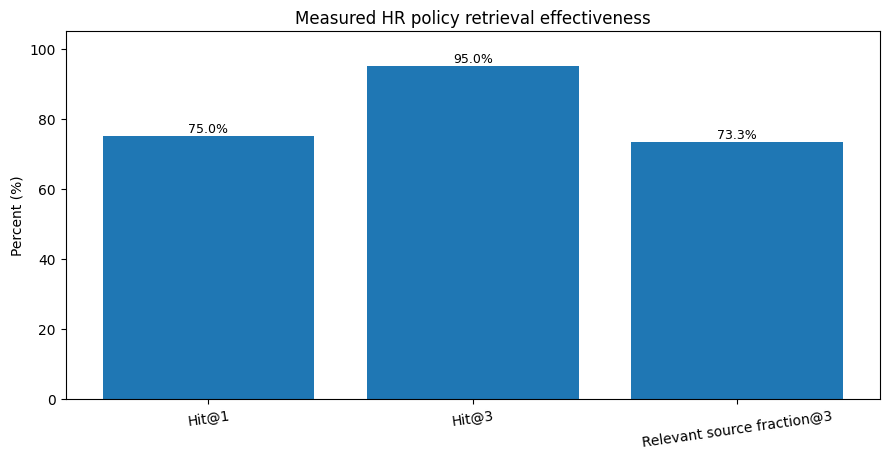

In [10]:
# Plot top-1 / top-3 document retrieval and mean source relevance.
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 4.7))
labels = ["Hit@1", "Hit@3", "Relevant source fraction@3"]
values = [retrieval_hit_1*100, retrieval_hit_3*100, source_precision_3*100]
bars = plt.bar(labels, values)
plt.ylim(0, 105)
plt.ylabel("Percent (%)")
plt.title("Measured HR policy retrieval effectiveness")
for bar, value in zip(bars, values):
    plt.text(bar.get_x()+bar.get_width()/2, value+1.2, f"{value:.1f}%", ha="center", fontsize=9)
plt.xticks(rotation=8)
plt.tight_layout()
plt.savefig(output_dir / "retrieval_quality.png", dpi=160, bbox_inches="tight")
plt.show()

## Graph — response time per question (measured)

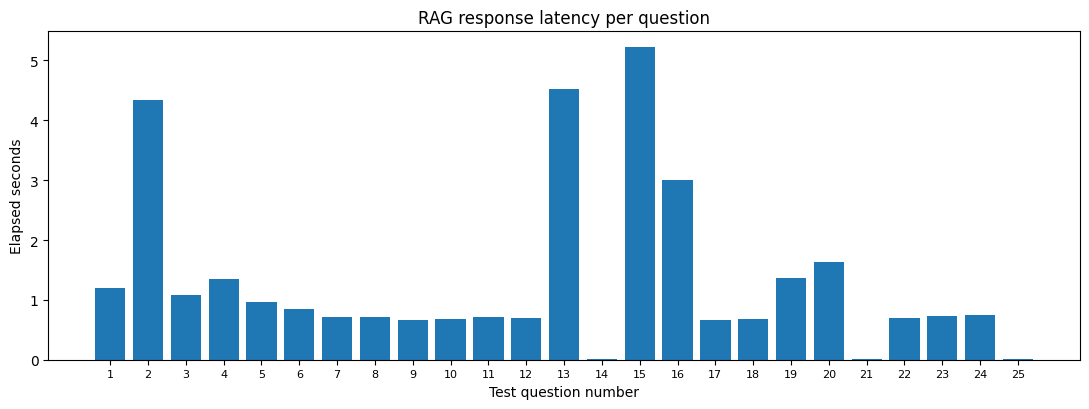

In [11]:
# Display all 25 measured response times in a separate chart.
plt.figure(figsize=(11, 4.2))
plt.bar(results_df["test_id"], results_df["latency_s"])
plt.xticks(results_df["test_id"], rotation=0, fontsize=8)
plt.ylabel("Elapsed seconds")
plt.xlabel("Test question number")
plt.title("RAG response latency per question")
plt.tight_layout()
plt.savefig(output_dir / "latency_by_question.png", dpi=160, bbox_inches="tight")
plt.show()

## Graph — observed answer and refusal outcomes

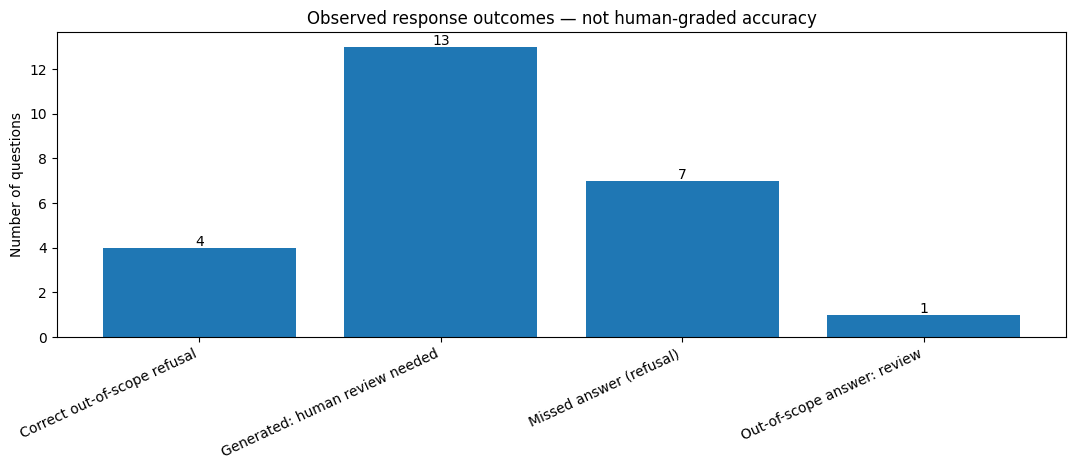

In [12]:
# Show measured statuses, keeping human-unverified answers separate from confirmed correctness.
counts = results_df["auto_outcome"].value_counts().sort_index()
plt.figure(figsize=(11, 4.8))
bars = plt.bar(counts.index, counts.values)
plt.ylabel("Number of questions")
plt.title("Observed response outcomes — not human-graded accuracy")
plt.xticks(rotation=25, ha="right")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+.1, int(bar.get_height()), ha="center")
plt.tight_layout()
plt.savefig(output_dir / "response_outcomes.png", dpi=160, bbox_inches="tight")
plt.show()

## Export results and independent correctness / faithfulness review template

In [13]:
# Save traceable metrics, all chunks, sample questions and a blank human review template.
import json
output_dir = Path("/content/drive/MyDrive/HR_RAG_Outputs") if Path("/content/drive/MyDrive").exists() else Path("/content/HR_RAG_Outputs")
output_dir.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_dir / "rag_test_results.csv", index=False)
chunks_df.to_csv(output_dir / "rag_source_chunks.csv", index=False)
pd.DataFrame(test_cases).to_csv(output_dir / "test_questions_and_expected_answers.csv", index=False)

review_columns = ["test_id", "question", "answerable", "expected_answer", "answer", "source_ids", "source_chunk_ids"]
review = results_df[review_columns].copy()
review["factually_correct_Y_N"] = ""
review["faithful_to_sources_Y_N"] = ""
review["retrieved_sources_relevant_Y_N"] = ""
review["safety_appropriate_Y_N"] = ""
review["reviewer_notes"] = ""
review_file = output_dir / "human_review_TO_COMPLETE.csv"
# Never overwrite reviewers' manual annotations.
if not review_file.exists():
    review.to_csv(review_file, index=False)

summary = {
    "dataset": "fictional ExampleCo HR-policy CSV",
    "dataset_policies": int(len(df)),
    "source_chunks": int(len(chunks_df)),
    "test_count": int(len(results_df)),
    "answerable_count": int(results_df["answerable"].sum()),
    "out_of_scope_count": int((~results_df["answerable"]).sum()),
    "retrieval_mode": retrieval_mode,
    "llm_mode": llm_mode,
    "retrieval_hit_at_1": retrieval_hit_1,
    "retrieval_hit_at_3": retrieval_hit_3,
    "mean_relevant_source_fraction_at_3": source_precision_3,
    "mean_latency_seconds": mean_latency,
    "correct_refusal_rate": None if llm_mode != "local_llm" else float(results_df["correct_refusal"].mean()),
    "lexical_answer_similarity_proxy": None if llm_mode != "local_llm" else float(results_df["expected_answer_lexical_f1_proxy"].mean()),
    "source_token_coverage_proxy_NOT_faithfulness": None if llm_mode != "local_llm" else float(results_df["evidence_token_coverage_proxy"].mean()),
    "human_verified_accuracy": None,
    "human_verified_faithfulness": None,
}
(output_dir / "metrics_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("All files saved in:", output_dir)
for file in sorted(output_dir.iterdir()):
    print(" -", file.name)
print("IMPORTANT: Fill factual correctness and faithfulness columns independently; no fictitious labels were added.")

All files saved in: /content/drive/MyDrive/HR_RAG_Outputs
 - human_review_TO_COMPLETE.csv
 - latency_by_question.png
 - metrics_summary.json
 - rag_source_chunks.csv
 - rag_test_results.csv
 - response_outcomes.png
 - retrieval_quality.png
 - test_questions_and_expected_answers.csv
IMPORTANT: Fill factual correctness and faithfulness columns independently; no fictitious labels were added.


## Evaluation rules, limitations and next steps

- **Retrieval relevance:** `retrieval_hit_at_1`, `retrieval_hit_at_3` and the mean fraction of retrieved chunks from the expected policy use known source IDs; these are measured and reproducible.
- **Automatic correctness proxy:** `expected_answer_lexical_f1_proxy` compares generated text with human-written reference text. It does **not** establish factual correctness; correct paraphrases can receive low scores.
- **Automatic faithfulness proxy:** `evidence_token_coverage_proxy` merely checks token overlap with retrieved passages; it does **not** prove that a claim is supported by the cited text.
- **True correctness and faithfulness:** Review every generated answer and the retrieved source manually. Fill in the blank review CSV with `Y`/`N`; run the next cell to calculate verified correctness, faithfulness, and correct / incorrect / unsupported totals. These scores are intentionally unavailable before review.
- **Refusals:** Five out-of-scope questions are included as safety/abstention probes; withholding an unsupported answer is desirable.
- **Limitations:** Fictional, short documents; manually drafted example questions; small single-model evaluation; potential language-model errors; no generalisation to real workplaces and no guarantee of Australian employment-law compliance.
- **Integrity:** RMIT Condition 3 prohibits AI-generated final assessable code, final analysis and reflections. Use this solely to understand techniques and independently produce the group's work.

## After manual review — verified accuracy, faithfulness and answer types

In [14]:
# Re-run after a reviewer has filled the saved human_review_TO_COMPLETE.csv file.
# Empty values stay unscored; charts never invent accuracy or faithfulness.
review_df = pd.read_csv(review_file, keep_default_na=False)
review_df["test_id"] = pd.to_numeric(review_df["test_id"], errors="coerce")
lookup = results_df[["test_id", "answerable", "status"]]
review_df = review_df.drop(columns=["answerable"], errors="ignore").merge(lookup, on="test_id", how="left")
answer_review = review_df.loc[(review_df["status"] == "generated_unverified")].copy()
for col in ["factually_correct_Y_N", "faithful_to_sources_Y_N", "retrieved_sources_relevant_Y_N", "safety_appropriate_Y_N"]:
    answer_review[col] = answer_review[col].astype(str).str.strip().str.upper()
verified = answer_review.loc[answer_review["factually_correct_Y_N"].isin(["Y", "N"])]
faithfulness_reviewed = answer_review.loc[answer_review["faithful_to_sources_Y_N"].isin(["Y", "N"])]

print("Generated answers reviewed for correctness:", len(verified), "/", len(answer_review))
print("Generated answers reviewed for faithfulness:", len(faithfulness_reviewed), "/", len(answer_review))
if len(verified):
    print(f"Human-verified correctness (reviewed generated answers): {(verified['factually_correct_Y_N'] == 'Y').mean():.1%}")
else:
    print("Human-verified correctness: PENDING reviewer annotations")
if len(faithfulness_reviewed):
    print(f"Human-verified faithfulness (reviewed generated answers): {(faithfulness_reviewed['faithful_to_sources_Y_N'] == 'Y').mean():.1%}")
else:
    print("Human-verified faithfulness: PENDING reviewer annotations")

if len(verified):
    generated_correct = int((verified["factually_correct_Y_N"] == "Y").sum())
    generated_incorrect = int((verified["factually_correct_Y_N"] == "N").sum())
    unsupported_generated = int(((verified["answerable"] == False) & (verified["factually_correct_Y_N"] == "N")).sum())
    num_unreviewed = len(answer_review) - len(verified)
    category_counts = {
        "Correct (reviewed)": generated_correct,
        "Incorrect (reviewed)": generated_incorrect,
        "Of incorrect: out-of-scope": unsupported_generated,
        "Generated unreviewed": num_unreviewed,
    }
    # The out-of-scope bar is a SUBSET of incorrect: do not sum all four bars.
    plt.figure(figsize=(10, 4.7))
    bars = plt.bar(category_counts.keys(), category_counts.values())
    plt.ylabel("Answer count")
    plt.title("Reviewed correctness and unsupported-answer count (subset shown)")
    plt.xticks(rotation=15, ha="right")
    for bar in bars:
        plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05, int(bar.get_height()), ha="center")
    plt.tight_layout()
    plt.savefig(output_dir / "manual_review_outcomes.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Correct / incorrect / unsupported-answer graph available only after manual review; no scores fabricated.")

Generated answers reviewed for correctness: 0 / 14
Generated answers reviewed for faithfulness: 0 / 14
Human-verified correctness: PENDING reviewer annotations
Human-verified faithfulness: PENDING reviewer annotations
Correct / incorrect / unsupported-answer graph available only after manual review; no scores fabricated.


## Optional: ask your own HR-policy question

In [15]:
# Change the following question to try retrieval and the local LLM.
YOUR_QUESTION = "How do I request remote work?"
custom_answer = ask_hr(YOUR_QUESTION)
print("Question:", custom_answer["question"])
print("Answer:", custom_answer["answer"])
print("Mode:", custom_answer["llm_mode"], "| Status:", custom_answer["status"])
for s in custom_answer["sources"]:
    print("Source:", s["policy_title"], "|", s["chunk_id"], "| Similarity:", s["similarity"])

Question: How do I request remote work?
Answer: Identify the proposed work pattern, preferred start date, length of the arrangement, and any equipment or accessibility needs. Requests should be discussed with the manager rather than assumed to be approved. [Flexible and Remote Working Arrangements] tten response within 15 working days. This is an internal illustrative target, not a legal deadline. Remote work practices When working remotely, employees must use approved devices, enable
Mode: local_llm | Status: generated_unverified
Source: Flexible and Remote Working Arrangements | 04_flexible_and_remote_work_chunk01 | Similarity: 0.4764
Source: Flexible and Remote Working Arrangements | 04_flexible_and_remote_work_chunk03 | Similarity: 0.4657
Source: Flexible and Remote Working Arrangements | 04_flexible_and_remote_work_chunk02 | Similarity: 0.4194
